<div align="center">

# 🐼 Pandas Complete Handbook
## Theory • Concepts • Terminology • Functionality • Interview Mastery

**Fundamentals to advanced workflows | Google Colab + Jupyter Notebook**

<span style="background:#dbeafe;color:#1d4ed8;padding:5px 10px;border-radius:12px"><b>THEORY + PRACTICE</b></span>
<span style="background:#dcfce7;color:#166534;padding:5px 10px;border-radius:12px"><b>ONE Q&A PER CELL</b></span>
<span style="background:#fef3c7;color:#92400e;padding:5px 10px;border-radius:12px"><b>COLAB FRIENDLY</b></span>

</div>

---

**Notebook structure:** each interview question and answer occupies its own Markdown cell. Theory sections are separate cells, practical examples are executable code cells, and the workflow diagram is generated with Matplotlib so it renders as an actual image in the cell output rather than relying on Mermaid.

### Learning path
1. Pandas mental model and core structures
2. Inspecting, selecting, filtering, and transforming
3. Cleaning, missing values, types, strings, and dates
4. Grouping, merging, reshaping, and time series
5. Performance, reliability, and production practices
6. 100+ interview questions: foundational, intermediate, advanced, scenario-based, and production-focused

**Environment:** Python 3 with Pandas, NumPy, and Matplotlib. Google Colab normally includes these packages.

## 1. 🧠 What is Pandas?

Pandas is a Python library for **labeled tabular and time-indexed data**. It supports loading, inspecting, cleaning, transforming, combining, summarizing, and exporting data.

Common uses:
- CSV, Excel, JSON, SQL, and Parquet data preparation
- Exploratory data analysis (EDA) and business reporting
- Joins between customer, order, product, or event tables
- Feature preparation for machine learning
- Date/time, event-log, and time-series analysis
- Data validation before downstream analytics

### Core terminology

| Term | Meaning |
|---|---|
| `Series` | One-dimensional labeled array |
| `DataFrame` | Two-dimensional labeled table with rows and columns |
| `Index` | Labels used to identify and align rows |
| `columns` | Column labels |
| `dtype` | Data type of a Series or column |
| Vectorization | Operating on whole arrays/columns rather than manually looping |
| Alignment | Operations match labels when appropriate |
| GroupBy | Split data into groups, apply operations, combine results |
| Reshaping | Change data layout, e.g. wide to long |
| Missing value | An absent/unknown value represented by markers such as `NaN`, `NA`, or `NaT` |

Pandas is not just a table viewer: **labels, alignment, indexing, and transformation semantics** are central to how it works.

## 2. 🗺️ A Pandas workflow diagram

The following code cell renders a real diagram using Matplotlib. It does not require Mermaid support.

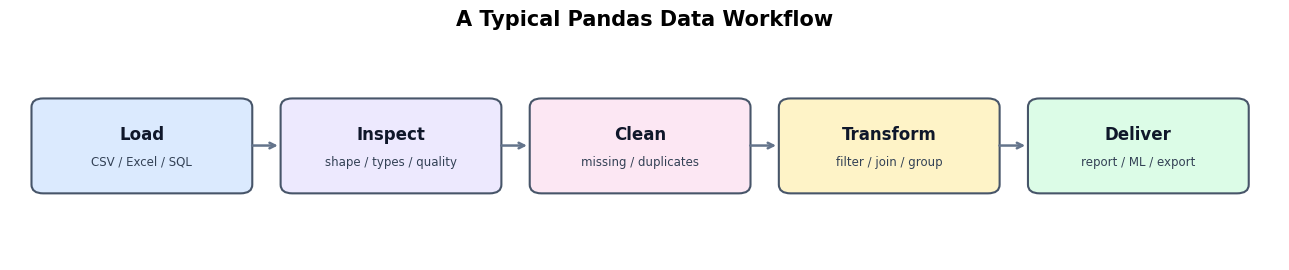

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 2.8))
ax.set_xlim(0, 13)
ax.set_ylim(0, 3)
ax.axis("off")

steps = [
    ("Load", "CSV / Excel / SQL"),
    ("Inspect", "shape / types / quality"),
    ("Clean", "missing / duplicates"),
    ("Transform", "filter / join / group"),
    ("Deliver", "report / ML / export"),
]
xs = [0.3, 2.85, 5.4, 7.95, 10.5]
colors = ["#DBEAFE", "#EDE9FE", "#FCE7F3", "#FEF3C7", "#DCFCE7"]

for i, ((title, subtitle), x, color) in enumerate(zip(steps, xs, colors)):
    patch = FancyBboxPatch((x, 1.0), 2.1, 1.15,
                           boxstyle="round,pad=0.08,rounding_size=0.12",
                           linewidth=1.5, edgecolor="#475569", facecolor=color)
    ax.add_patch(patch)
    ax.text(x + 1.05, 1.72, title, ha="center", va="center",
            fontsize=12, fontweight="bold", color="#0F172A")
    ax.text(x + 1.05, 1.35, subtitle, ha="center", va="center",
            fontsize=8.5, color="#334155")
    if i < len(steps) - 1:
        ax.annotate("", xy=(xs[i+1] - 0.08, 1.58), xytext=(x + 2.15, 1.58),
                    arrowprops=dict(arrowstyle="->", lw=1.8, color="#64748B"))
ax.set_title("A Typical Pandas Data Workflow", fontsize=15, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

## 3. 🧱 Series, DataFrame, and indexing

- A **Series** is one labeled vector: values plus an index.
- A **DataFrame** is a table with row and column axes; columns may have different dtypes.
- `.loc` is label-based; `.iloc` is integer-position-based.
- `.at` and `.iat` are optimized for scalar access.
- Pandas often aligns Series by index labels rather than assigning strictly by position.

| Property / method | Purpose |
|---|---|
| `shape` | Row/column count |
| `columns`, `index` | Labels |
| `dtypes` | Per-column types |
| `head()`, `tail()`, `sample()` | Inspect records |
| `info()` | Non-null counts, dtypes, memory summary |
| `describe()` | Descriptive statistics |
| `value_counts()` | Frequency counts |
| `nunique()` | Unique-value count |
| `isna().sum()` | Missingness by column |
| `duplicated().sum()` | Duplicate-row count |

In [24]:
students = pd.DataFrame({
    "name": ["Asha", "Ben", "Chen", "Dia"],
    "age": [28, 35, 22, 41],
    "city": ["Bengaluru", "Mumbai", "Bengaluru", "Delhi"],
    "score": [88, 92, 79, 84],
}, index=["u1", "u2", "u3", "u4"])

display(students.head(3))
print("Shape:", students.shape)
print("Dtypes:\n", students.dtypes)
display(students.describe(include="all").T)
display(students.loc["u2", ["age", "city"]])
display(students.iloc[0:2, 0:3])
display(students.loc[(students["score"] >= 85) & (students["city"] == "Bengaluru")])

,name,age,city,score
u1,Asha,28,Bengaluru,88
u2,Ben,35,Mumbai,92
u3,Chen,22,Bengaluru,79


Shape: (4, 4)
Dtypes:
 name     object
age       int64
city     object
score     int64
dtype: object


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,4,4,Asha,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,4.0,NaN,NaN,NaN,31.5,8.266398,22.0,26.5,31.5,36.5,41.0
city,4,3,Bengaluru,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
score,4.0,NaN,NaN,NaN,85.75,5.560276,79.0,82.75,86.0,89.0,92.0


,u2
age,35
city,Mumbai


,name,age,city
u1,Asha,28,Bengaluru
u2,Ben,35,Mumbai


,name,age,city,score
u1,Asha,28,Bengaluru,88


## 4. 🔎 Selecting, filtering, and assigning

- `df['col']` selects one column as a Series.
- `df[['a', 'b']]` selects multiple columns as a DataFrame.
- Boolean masks filter rows; use `&`, `|`, and `~`, with parentheses around comparisons.
- Use `.loc[condition, column] = value` for safe conditional assignment.
- Avoid chained assignment such as `df[mask]['col'] = value`.
- `query()` can make some filters readable, but boolean indexing is more general.

In [14]:
people = pd.DataFrame({
    "name": ["Asha", "Ben", "Chen", "Dia"],
    "age": [28, 35, 22, 41],
    "spend": [1200, 900, 1500, 700],
})
people.loc[people["age"] < 25, "age_group"] = "young"
people.loc[people["age"] >= 25, "age_group"] = "adult"
display(people)
display(people.loc[(people["spend"] >= 1000) & (people["age"] < 35)])

,name,age,spend,age_group
0,Asha,28,1200,adult
1,Ben,35,900,adult
2,Chen,22,1500,young
3,Dia,41,700,adult


,name,age,spend,age_group
0,Asha,28,1200,adult
2,Chen,22,1500,young


## 5. 🧼 Cleaning, missing values, and data types

Common quality tasks include identifying missingness, deciding what duplicates mean, parsing dates, converting numeric strings, standardizing categories, and validating business rules.

| Need | Common API | Important caution |
|---|---|---|
| Detect missingness | `isna()`, `notna()` | Missingness may carry meaning |
| Remove missing rows | `dropna()` | Document which rows are removed |
| Fill missing values | `fillna()` | Zero is not a universal replacement |
| Remove duplicates | `drop_duplicates()` | Define duplicate identity and retention rule |
| Convert numeric | `to_numeric()` | Choose how invalid values are handled |
| Parse dates | `to_datetime()` | Be explicit about format/timezone |
| Cast dtype | `astype()` | Ensure cast preserves meaning |
| Normalize text | `.str.strip()`, `.str.lower()` | Preserve true distinctions |
| Inspect categories | `unique()`, `value_counts()` | Watch unknown or rare values |

`NaN` is commonly used for missing floating-point values, `pd.NA` is a general missing marker used with nullable dtypes, and `NaT` represents missing datetime/timedelta values.

In [15]:
dirty = pd.DataFrame({
    "customer": [" Asha ", "BEN", "Ben", None, "Chen"],
    "age": ["28", "35", None, "41", "22"],
    "amount": [120.0, np.nan, 90.0, 700.0, 150.0],
    "date": ["2026-01-01", "2026-01-02", "bad-date", "2026-01-04", "2026-01-05"],
})
dirty["customer"] = dirty["customer"].str.strip().str.title()
dirty["age"] = pd.to_numeric(dirty["age"], errors="coerce")
dirty["date"] = pd.to_datetime(dirty["date"], errors="coerce")
display(dirty)
display(dirty.isna().sum().to_frame("missing_count"))
dirty["amount"] = dirty["amount"].fillna(dirty["amount"].median())
display(dirty)

,customer,age,amount,date
0,Asha,28.0,120.0,2026-01-01
1,Ben,35.0,NaN,2026-01-02
2,Ben,NaN,90.0,NaT
3,None,41.0,700.0,2026-01-04
4,Chen,22.0,150.0,2026-01-05


,missing_count
customer,1
age,1
amount,1
date,1


,customer,age,amount,date
0,Asha,28.0,120.0,2026-01-01
1,Ben,35.0,135.0,2026-01-02
2,Ben,NaN,90.0,NaT
3,None,41.0,700.0,2026-01-04
4,Chen,22.0,150.0,2026-01-05


## 6. 🧮 Transformations and feature creation

Prefer vectorized arithmetic, `.str` and `.dt` accessors, boolean masks, `where()`, `map()`, and NumPy functions when they express the logic. `apply(axis=1)` can be slower because it invokes Python-level logic for each row.

- `assign()` creates or replaces columns and supports method chaining.
- `map()` maps values in a Series.
- `replace()` substitutes matching values.
- `where()` keeps values where a condition is true.
- `rename()` changes labels; `drop()` removes rows or columns.
- `pipe()` helps compose named transformation functions.

In [16]:
orders = pd.DataFrame({
    "order_id": [1, 2, 3, 4],
    "units": [2, 1, 4, 3],
    "unit_price": [250.0, 120.0, 80.0, 250.0],
    "status": ["complete", "cancelled", "complete", "pending"],
})
orders["gross_amount"] = orders["units"] * orders["unit_price"]
orders["is_completed"] = orders["status"].eq("complete")
orders["status_group"] = orders["status"].map({
    "complete": "closed", "cancelled": "closed", "pending": "open"
})
orders = orders.assign(net_amount=lambda d: d["gross_amount"] * 0.95)
display(orders)

,order_id,units,unit_price,status,gross_amount,is_completed,status_group,net_amount
0,1,2,250.0,complete,500.0,True,closed,475.0
1,2,1,120.0,cancelled,120.0,False,closed,114.0
2,3,4,80.0,complete,320.0,True,closed,304.0
3,4,3,250.0,pending,750.0,False,open,712.5


## 7. 📊 Grouping and aggregation

The **split–apply–combine** pattern:
1. Split rows into groups using keys.
2. Apply aggregations or transformations.
3. Combine the results.

- `groupby().agg()` produces group-level summaries.
- `groupby().transform()` returns group-derived values aligned to original rows.
- `size()` counts rows; `count()` counts non-missing values.
- `filter()` keeps or removes entire groups based on a condition.
- `nunique()` counts distinct values within groups.

In [17]:
transactions = pd.DataFrame({
    "region": ["South", "West", "South", "East", "West", "South"],
    "product": ["A", "A", "B", "B", "A", "B"],
    "revenue": [500, 120, 320, 750, 180, 280],
    "units": [2, 1, 4, 3, 2, 2],
})
summary = transactions.groupby("region").agg(
    total_revenue=("revenue", "sum"),
    average_revenue=("revenue", "mean"),
    transaction_count=("revenue", "size"),
    product_count=("product", "nunique"),
)
display(summary.sort_values("total_revenue", ascending=False))
transactions["region_avg_revenue"] = transactions.groupby("region")["revenue"].transform("mean")
display(transactions)

,total_revenue,average_revenue,transaction_count,product_count
region,,,,
South,1100,366.666667,3,2
East,750,750.000000,1,1
West,300,150.000000,2,1


,region,product,revenue,units,region_avg_revenue
0,South,A,500,2,366.666667
1,West,A,120,1,150.000000
2,South,B,320,4,366.666667
3,East,B,750,3,750.000000
4,West,A,180,2,150.000000
5,South,B,280,2,366.666667


## 8. 🔗 Merge, join, and concatenate

- `pd.merge()` combines DataFrames using matching keys; it resembles relational joins.
- `DataFrame.join()` is convenient for index-oriented joins.
- `pd.concat()` stacks objects along rows or columns.
- Join types: `inner`, `left`, `right`, and `outer`.
- `validate=` checks expected key cardinality such as one-to-one or many-to-one.
- `indicator=True` labels whether a joined row came from the left, right, or both.

**Production caution:** duplicate keys on both sides can multiply rows. Validate key uniqueness, row counts, and intended join cardinality.

In [18]:
customers = pd.DataFrame({"customer_id": [1, 2, 3], "name": ["Asha", "Ben", "Chen"]})
purchases = pd.DataFrame({"customer_id": [1, 1, 3, 4], "amount": [100, 250, 90, 70]})
customer_view = customers.merge(
    purchases, on="customer_id", how="left",
    validate="one_to_many", indicator=True
)
display(customer_view)
display(pd.concat([
    pd.DataFrame({"month": ["Jan"], "revenue": [1000]}),
    pd.DataFrame({"month": ["Feb"], "revenue": [1200]})
], ignore_index=True))

,customer_id,name,amount,_merge
0,1,Asha,100.0,both
1,1,Asha,250.0,both
2,2,Ben,NaN,left_only
3,3,Chen,90.0,both


,month,revenue
0,Jan,1000
1,Feb,1200


## 9. 🔀 Reshaping and tidy data

- **Long/tidy format:** each variable is a column and each observation is a row.
- **Wide format:** categories or measures are spread across columns.
- `melt()` converts wide to long.
- `pivot()` converts long to wide and requires unique index/column combinations.
- `pivot_table()` can aggregate duplicate combinations.
- `stack()` moves column levels into the index; `unstack()` moves index levels into columns.
- `explode()` converts list-like values into multiple rows.

In [19]:
wide = pd.DataFrame({"store": ["North", "South"], "Jan": [100, 120], "Feb": [130, 110], "Mar": [125, 140]})
long = wide.melt(id_vars="store", var_name="month", value_name="sales")
display(long)
display(long.pivot(index="store", columns="month", values="sales"))

,store,month,sales
0,North,Jan,100
1,South,Jan,120
2,North,Feb,130
3,South,Feb,110
4,North,Mar,125
5,South,Mar,140


month,Feb,Jan,Mar
store,,,
North,130,100,125
South,110,120,140


## 10. 🗓️ Strings, dates, categories, and indexes

- String operations use `.str`, such as `.str.strip()`, `.str.lower()`, `.str.contains()`, and `.str.replace()`.
- Parse dates with `pd.to_datetime()`; use `.dt` to access year, month, weekday, and other components.
- `category` dtype can reduce memory for repeated values and preserve category order.
- `set_index()`, `reset_index()`, `reindex()`, and `sort_index()` manage row labels.
- Timezone localization assigns a timezone; timezone conversion changes an aware timestamp to another timezone.
- An index is not automatically a unique primary key; enforce uniqueness if required.

In [20]:
events = pd.DataFrame({
    "user": [" Asha", "BEN ", "Chen", "Asha"],
    "timestamp": ["2026-01-01 10:30", "2026-01-01 11:00", "2026-01-02 09:15", "2026-01-02 12:00"],
    "event": ["click", "purchase", "click", "view"],
    "segment": ["regular", "vip", "regular", "regular"],
})
events["user"] = events["user"].str.strip().str.title()
events["timestamp"] = pd.to_datetime(events["timestamp"])
events["day"] = events["timestamp"].dt.date
events["hour"] = events["timestamp"].dt.hour
events["segment"] = events["segment"].astype("category")
display(events)
display(events.groupby("day", observed=True).size().rename("events_per_day").to_frame())

,user,timestamp,event,segment,day,hour
0,Asha,2026-01-01 10:30:00,click,regular,2026-01-01,10
1,Ben,2026-01-01 11:00:00,purchase,vip,2026-01-01,11
2,Chen,2026-01-02 09:15:00,click,regular,2026-01-02,9
3,Asha,2026-01-02 12:00:00,view,regular,2026-01-02,12


,events_per_day
day,
2026-01-01,2
2026-01-02,2


## 11. ⏱️ Time-series functionality

- `resample()` groups a time series into bins such as days or weeks and typically aggregates each bin.
- `rolling()` computes a moving-window statistic.
- `shift()` moves values across rows and is useful for lag features.
- `diff()` computes differences between adjacent observations.
- `asfreq()` conforms a series to a frequency without aggregating.
- `tz_localize()` assigns a timezone to naive timestamps; `tz_convert()` converts an aware index.

**Leakage warning:** for forecasting, do not use future information in features. Backward fill, centered rolling windows, or incorrectly aligned shifts can leak future values.

In [21]:
daily = pd.DataFrame({
    "timestamp": pd.date_range("2026-01-01", periods=10, freq="D"),
    "demand": [20, 22, 19, 25, 28, 27, 30, 26, 31, 35],
}).set_index("timestamp")
daily["previous_day"] = daily["demand"].shift(1)
daily["change"] = daily["demand"].diff()
daily["rolling_3_day_mean"] = daily["demand"].rolling(3, min_periods=1).mean()
display(daily)
display(daily["demand"].resample("W").sum().to_frame("weekly_demand"))

,demand,previous_day,change,rolling_3_day_mean
timestamp,,,,
2026-01-01,20,NaN,NaN,20.000000
2026-01-02,22,20.0,2.0,21.000000
2026-01-03,19,22.0,-3.0,20.333333
2026-01-04,25,19.0,6.0,22.000000
2026-01-05,28,25.0,3.0,24.000000
2026-01-06,27,28.0,-1.0,26.666667
2026-01-07,30,27.0,3.0,28.333333
2026-01-08,26,30.0,-4.0,27.666667
2026-01-09,31,26.0,5.0,29.000000


,weekly_demand
timestamp,
2026-01-04,86
2026-01-11,177


## 12. ⚡ Performance, memory, and production quality

1. Prefer vectorized operations over Python loops and row-wise `apply()` when possible.
2. Read only required columns using `usecols`; use chunking when a workflow supports it.
3. Measure memory with `memory_usage(deep=True)` and choose dtypes based on real workload.
4. Avoid repeated concatenation inside loops; collect chunks and concatenate once.
5. Consider Parquet for repeated analytical workloads and schema preservation.
6. Validate schema, null rates, ranges, categories, key uniqueness, and join cardinality.
7. Use explicit `.loc` assignment rather than chained assignment.
8. Pin dependency versions and test transformations on realistic data.
9. Pandas is primarily in-memory; for data larger than available RAM, use chunking or a suitable out-of-core/distributed tool.

In [22]:
def audit_dataframe(df):
    # Compact column-level data-quality summary.
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2),
        "unique_count": df.nunique(dropna=True),
    }).sort_values("missing_pct", ascending=False)

display(audit_dataframe(events))
assert "timestamp" in events.columns
assert events["user"].notna().all()

,dtype,missing_count,missing_pct,unique_count
user,object,0,0.0,3
timestamp,datetime64[ns],0,0.0,4
event,object,0,0.0,3
segment,category,0,0.0,2
day,object,0,0.0,2
hour,int32,0,0.0,4


## 13. 🧭 API selection quick reference

| Need | Start with | Watch out for |
|---|---|---|
| Load CSV | `read_csv()` | encoding, separators, dtype inference |
| Load Excel | `read_excel()` | sheet and engine |
| Load JSON | `read_json()`, `json_normalize()` | nested structure |
| Load Parquet | `read_parquet()` | compatible engine |
| Read SQL | `read_sql()` | query and connection management |
| Inspect | `info()`, `shape`, `dtypes` | inspection is not full validation |
| Select | `.loc[]`, `.iloc[]` | labels vs positions |
| Filter | boolean masks, `query()` | parentheses and missing values |
| Clean | `isna()`, `fillna()`, `drop_duplicates()` | domain meaning |
| Summarize | `groupby().agg()` | `size()` vs `count()` |
| Join | `merge()` | duplicate keys and row multiplication |
| Reshape | `melt()`, `pivot()`, `pivot_table()` | uniqueness and aggregation |
| Dates | `to_datetime()`, `.dt` | timezones and parsing rules |
| Time aggregation | `resample()`, `rolling()` | time index and leakage |
| Export | `to_csv()`, `to_parquet()`, `to_excel()` | index/schema choices |

## 14. 🎤 Interview question bank

**Each question and answer below is a separate Markdown cell.** Collapse or expand individual cells using the notebook's cell controls. The bank covers basics, intermediate concepts, advanced APIs, debugging, scenario questions, and production practices.

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q1. What is Pandas?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A Python library for labeled tabular and time-indexed data, used to load, clean, transform, join, aggregate, reshape, and export datasets.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q2. Why is Pandas used in data science?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It makes data preparation and exploratory analysis expressive and integrates with NumPy, visualization libraries, SQL workflows, and ML tools.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q3. What are the two main Pandas data structures?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Series and DataFrame. A Series is one-dimensional and labeled; a DataFrame is a two-dimensional labeled table.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q4. What is a Series?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A labeled one-dimensional array containing values and an index, optionally with a name.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q5. What is a DataFrame?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A labeled two-dimensional table whose columns can have different data types.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q6. What is an Index?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
The row or column labels used for selection and alignment. An index is not automatically a unique primary key.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q7. What does `shape` return?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A tuple containing the number of rows and columns.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q8. What is the difference between `head()` and `tail()`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`head(n)` shows the first n rows; `tail(n)` shows the last n rows.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q9. What does `info()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Summarizes columns, non-null counts, dtypes, index information, and memory usage.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q10. What does `describe()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Computes descriptive statistics; by default it summarizes numeric columns, with options for other types.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q11. What is the difference between `size` and `shape`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`shape` gives row and column counts; `size` gives total element count.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q12. What does `dtypes` show?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
The dtype of each column, useful for finding numeric strings, unparsed dates, and unexpected object columns.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q13. How do you select one column?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`df['column']` returns a Series; `df[['column']]` returns a one-column DataFrame.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q14. What is the difference between `loc` and `iloc`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`.loc` selects by label; `.iloc` selects by integer position. Label slicing and positional slicing have different end-point behavior.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q15. What are `at` and `iat`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Scalar accessors: `at` uses labels and `iat` uses integer positions.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q16. How do you filter with multiple conditions?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Combine parenthesized boolean comparisons using `&` for AND, `|` for OR, and `~` for NOT.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q17. Why do boolean filters need parentheses?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Python operator precedence can otherwise change the intended expression; parentheses make the logic explicit.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q18. What is boolean indexing?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Selecting rows or values using a Boolean mask where True identifies the entries to keep.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q19. What is the difference between `query()` and boolean indexing?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`query()` offers a readable expression syntax for many filters; boolean indexing is more general and works naturally with precomputed masks.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q20. What is chained indexing?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Selecting through multiple indexing operations, such as `df[mask]['col']`. Assignment can be ambiguous; use `.loc` on the intended DataFrame.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q21. How should you assign values conditionally?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use `.loc[condition, column] = value` to explicitly identify target rows and column.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q22. What is vectorization?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Operating on whole arrays or columns using optimized library routines instead of manually iterating through Python objects.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q23. Why can `apply(axis=1)` be slow?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It calls Python logic for each row. Vectorized operations and built-in accessors are usually more efficient.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q24. What is the difference between `map`, `apply`, and `DataFrame.map`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`Series.map()` maps Series values; `apply()` applies a function along an axis; `DataFrame.map()` applies elementwise in modern Pandas. `applymap()` is deprecated in recent Pandas.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q25. How do you rename columns?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use `rename(columns={'old': 'new'})`, or assign a new list to `df.columns` if replacing the full schema.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q26. How do you drop a column?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use `df.drop(columns=['column'])` and assign the result when you want a new DataFrame.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q27. How do you add a new column?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Assign an expression such as `df['total'] = df['quantity'] * df['price']`; Series assignment aligns by index labels.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q28. What does `assign()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Returns a DataFrame with added or replaced columns and is useful in method chains.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q29. What does `where()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Keeps values where a condition is True and replaces values where it is False.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q30. What is the difference between `replace()` and `map()`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`replace()` substitutes specified values and leaves unmatched values unchanged by default; `map()` maps Series values and may yield missing values for unmapped keys.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q31. How do you find missing values?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use `isna()` or `notna()`; `df.isna().sum()` counts missing values by column.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q32. What is the difference between `NaN`, `NA`, and `NaT`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`NaN` is a floating-point missing marker, `pd.NA` is a general missing marker for nullable dtypes, and `NaT` marks missing datetime/timedelta values.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q33. How do you remove missing rows?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use `dropna()` with explicit `subset`, `how`, or `thresh` rules, based on the meaning of missingness.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q34. How do you fill missing values?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use `fillna()` with a documented strategy. Zero is not a universal substitute for missing data.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q35. What is forward fill?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`ffill` propagates the last valid value forward; it is suitable only when carrying the prior state is meaningful.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q36. What is backward fill?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`bfill` uses the next valid value to fill earlier gaps. It can leak future information in prediction tasks.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q37. How do you detect duplicates?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use `duplicated()` to produce a Boolean mask and `.sum()` to count duplicates; specify `subset` if needed.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q38. How do you remove duplicates?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use `drop_duplicates(subset=..., keep=...)` after defining duplicate identity and which record should remain.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q39. Why not drop duplicates blindly?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Repeated rows may be legitimate events; removing them can distort counts and business outcomes.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q40. How do you convert a column to numeric?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use `pd.to_numeric()` with an explicit policy for invalid values, such as `errors='coerce'` or `errors='raise'`.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q41. How do you parse dates?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use `pd.to_datetime()`, preferably with an explicit format when known, and define invalid-value and timezone handling.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q42. What does `astype()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Casts a Series or DataFrame to a specified dtype; verify that the cast preserves meaning.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q43. What are nullable dtypes?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Pandas types such as `Int64`, `boolean`, and `string` that support missing values while retaining a logical dtype.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q44. What is categorical dtype?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A dtype that stores values as categories and can reduce memory for repeated values; benefit depends on cardinality and usage.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q45. What does `value_counts()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Counts unique values in a Series. Use `dropna=False` when missing values should be counted.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q46. What does `nunique()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Counts distinct values, excluding missing values by default.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q47. What is `groupby()`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Groups rows by keys so aggregation, transformation, or filtering can be performed per group.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q48. What is the difference between `agg()` and `transform()`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`agg()` typically returns a group-level summary; `transform()` returns group-derived values aligned to original rows.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q49. What is the difference between groupby `size()` and `count()`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`size()` counts rows; `count()` counts non-missing values in a Series or column.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q50. How do you perform multiple aggregations?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use named aggregation with `groupby().agg()`, specifying output names and aggregation functions.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q51. What does groupby `filter()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Retains or removes entire groups according to a condition evaluated per group.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q52. What is `merge()` used for?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Combines DataFrames using matching key columns or indexes, similar to relational joins.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q53. Explain inner, left, right, and outer joins.</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Inner keeps matches; left preserves all left keys; right preserves all right keys; outer preserves keys from both sides.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q54. Why can a merge increase row count unexpectedly?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Duplicate keys can create multiple combinations. Check uniqueness and use `validate=` to assert expected cardinality.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q55. What does `validate=` do in `merge()`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Checks expected relationships such as one-to-one, one-to-many, or many-to-one.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q56. What does `indicator=True` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Adds a merge indicator showing whether a row came from the left, right, or both inputs.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q57. What is the difference between `merge()` and `join()`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`merge()` is flexible for column-key joins; `join()` is convenient for index-oriented joins.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q58. What does `concat()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Combines Series or DataFrames along rows or columns.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q59. Why avoid repeated concatenation in a loop?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Repeated concatenation may repeatedly allocate and copy data; collecting chunks and concatenating once is often more efficient.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q60. What is the difference between `pivot()` and `pivot_table()`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`pivot()` requires unique index/column combinations; `pivot_table()` can aggregate duplicates.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q61. What does `melt()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Transforms wide data into long form by moving selected column names and values into variable/value columns.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q62. What are wide and long formats?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Wide spreads measures across columns; long stores variable names and values in rows. Long/tidy format often suits grouped analysis and plotting.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q63. What does `explode()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Expands list-like values into multiple rows, repeating the other columns as needed.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q64. What do `stack()` and `unstack()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`stack()` moves column levels into the index; `unstack()` moves index levels into columns.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q65. How do you use string methods?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use `.str`, for example `.str.strip()`, `.str.lower()`, `.str.contains()`, and `.str.replace()`, while handling missing values and regex behavior.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q66. How do you standardize text categories?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Normalize whitespace/case and apply explicit mappings for known aliases; do not merge values unless their meanings are equivalent.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q67. What does `.dt` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Exposes datetime components and operations on datetime-like Series, such as year, month, weekday, and date flooring.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q68. What is `resample()`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Groups time-indexed observations into frequency bins and typically aggregates them, such as daily data into weekly totals.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q69. What is the difference between `resample()` and `rolling()`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`resample()` groups observations into frequency bins; `rolling()` computes a moving-window statistic.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q70. What does `shift()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Moves values relative to the index, commonly for lags and prior-period comparisons.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q71. What does `diff()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Computes differences between an element and an earlier element, commonly the prior row.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q72. What is a MultiIndex?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A hierarchical index with multiple levels, useful for multi-key or grouped data.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q73. What does `set_index()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Uses one or more columns as the row index, removing them from columns by default.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q74. What does `reset_index()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Resets the index to a default integer index and usually inserts the old index into columns.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q75. What is index alignment?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Pandas matches values by index labels for many operations, which can reorder results or introduce missing values when labels differ.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q76. Why can assigning a Series create unexpected missing values?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Series assignment aligns by labels, not merely position; unmatched labels can become missing.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q77. How do you inspect memory?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use `memory_usage(deep=True)` or `info(memory_usage='deep')` for more realistic estimates, especially for object/string columns.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q78. How can category dtype save memory?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Repeated values can be stored as integer codes plus a category dictionary instead of repeated strings.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q79. How do you read selected CSV columns?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Pass `usecols=[...]` to `pd.read_csv()` to reduce parsing and memory work.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q80. How do you read a large CSV in chunks?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use `chunksize=...` in `read_csv()` and process each chunk; the workflow must not require the whole dataset in memory.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q81. What is Parquet?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A columnar file format often efficient for analytical workloads and better at preserving schema than plain CSV.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q82. CSV versus Parquet?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
CSV is broadly portable text but often loses schema and can be slower/larger; Parquet is typed and columnar, often useful for repeated analytics.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q83. How do you export CSV without index?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use `df.to_csv(path, index=False)` unless the index is part of the intended output.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q84. What does `copy()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Creates a copy of a DataFrame or Series, with details influenced by Pandas' memory and Copy-on-Write behavior. Prefer explicit assignment patterns.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q85. What is Copy-on-Write?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A memory behavior intended to make mutation more predictable by copying data when needed; behavior and defaults depend on Pandas version.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q86. What is SettingWithCopyWarning?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A warning associated with assignment through a potentially derived view. Avoid chained assignment and use `.loc` on the intended object.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q87. What is `pipe()`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Passes an object into a function to compose transformations in readable, testable pipelines.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q88. What is `DataFrame.eval()`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Evaluates supported expressions involving columns and can help in some workloads; it is not always faster and should not evaluate untrusted expressions.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q89. What is the difference between DataFrame `count()` and `size`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`count()` counts non-missing entries per column; `size` is total element count. In a groupby context, `size()` counts rows per group.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q90. How do you compare two DataFrames?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use `equals()`, `compare()`, aligned differences, schema checks, or key-based reconciliation depending on whether labels, order, dtype, and missingness must match.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q91. What does `DataFrame.compare()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Highlights differences between two similarly labeled DataFrames.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q92. How do you validate a schema?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Check required columns, dtypes, duplicate labels, null rates, allowed categories, value ranges, key uniqueness, and business invariants.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q93. What is data leakage in Pandas preprocessing?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A transformation uses future/target information or learns from held-out data. Fit learned preprocessing on training data only and preserve temporal boundaries.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q94. How can Pandas create time-series leakage?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Backward filling across a prediction boundary, centered rolling windows, or misaligned shifts can expose future values.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q95. How do you avoid row-wise loops?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use vectorized arithmetic, `.str`, `.dt`, masks, `where`, `groupby`, and NumPy functions when they express the task clearly.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q96. When is `apply()` appropriate?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
When the logic cannot be expressed clearly with built-in vectorized or group operations; benchmark on realistic data.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q97. What does `sort_values()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Sorts rows by one or more column values; specify direction and tie handling when required.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q98. What does `sort_index()` do?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Sorts rows by index labels, useful when label order or time order matters.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q99. What is the difference between `duplicated()` and `drop_duplicates()`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
`duplicated()` returns a mask; `drop_duplicates()` returns a DataFrame with duplicates removed.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q100. How should you handle outliers?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Investigate source quality and domain meaning first; an extreme value may be an error, a rare valid event, or a different process.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q101. How do you calculate group contribution percentages?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Aggregate by group and divide each group total by the intended overall denominator; verify the population represented by the denominator.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q102. How do you rank within groups?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use `groupby(...)[column].rank(...)` and specify direction and tie handling.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q103. What is `pd.crosstab()`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Builds a frequency table for combinations of categorical variables and can normalize or aggregate values.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q104. What is `pd.cut()`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Bins continuous values into defined intervals; specify edges and decide how out-of-range values are handled.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q105. What is `pd.qcut()`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Bins values using quantiles. Tied values may create duplicate edges, so inspect behavior and choose a policy.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q106. How do you detect unknown categories?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Compare observed values against an allowed set and report unknown values explicitly instead of silently mapping them to a valid category.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q107. How do you safely merge customer and transaction data?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Check customer-key uniqueness, select the intended join type, use `validate=`, inspect unmatched keys with `indicator=True`, and compare row counts.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q108. Why should merge key dtypes match?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Mismatched representations can prevent matches or raise errors. Normalize keys while preserving identifier semantics such as leading zeros.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q109. What is a many-to-many merge risk?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Duplicate keys on both sides can multiply combinations and inflate totals; validate cardinality and resolve duplicates only using a defensible rule.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q110. How do you process data larger than RAM?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Select fewer columns, use suitable dtypes, process chunks when possible, or choose an out-of-core/distributed tool. Pandas is primarily in-memory.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q111. How do you make a Pandas pipeline maintainable?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use named transformation functions, explicit schemas, stable outputs, tests, assertions, versioned dependencies, and documented rules.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q112. What should production data-quality checks include?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Schema, dtypes, missingness, ranges, freshness, allowed categories, key uniqueness, join cardinality, and business invariants.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q113. How do you debug a wrong aggregation?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Check input rows, grouping keys, missing-key behavior, duplicates, aggregation function, and whether `count()` or `size()` is intended.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q114. Why can groupby omit missing keys?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
By default, missing group keys may be excluded. Use `dropna=False` when missing keys should form a group and test behavior for your Pandas version.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q115. What does `observed` mean in categorical groupby?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It controls whether only observed category combinations appear or unobserved categorical combinations are included; set it explicitly if output shape matters.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q116. How do you make Pandas results reproducible?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Version inputs and dependencies, document parsing and ordering assumptions, control random sampling seeds, and test schema and output invariants.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q117. What are common Pandas performance bottlenecks?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Object/string-heavy columns, unnecessary copies, repeated concatenation, row-wise functions, expensive joins, and large intermediate objects.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q118. Pandas versus NumPy?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
NumPy provides n-dimensional arrays and numerical operations; Pandas adds labeled axes, heterogeneous columns, missing-data handling, joins, grouping, and time-aware functionality.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q119. Pandas versus SQL?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
SQL queries database systems declaratively; Pandas operates on Python data structures, typically in memory. Data scale, execution planning, and transaction needs affect the choice.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q120. Pandas versus Polars?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Pandas is mature and broadly integrated; Polars emphasizes a query engine, lazy execution, and parallel processing. Choose based on workload and measured results.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q121. How do you explain a Pandas project in an interview?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Describe the business question, data source and schema, quality problems, transformation rules, validation, performance constraints, output users, and measured result.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q122. How would you clean a new dataset?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Profile schema, missingness, duplicates, distributions, and domain constraints; define reproducible rules; validate outputs; document changes; and avoid leakage.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q123. What is the most important habit for Pandas correctness?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Make assumptions explicit about labels, dtypes, missingness, join cardinality, time boundaries, and output schema, then validate them with tests.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q124. How do you decide between dropping and imputing missing values?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Understand why values are missing, the amount and pattern of missingness, and downstream consequences. Choose and document a strategy rather than applying a universal rule.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q125. How do you validate a merge result?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Check row counts, unmatched keys, duplicate keys, expected cardinality, null changes, and totals before and after joining.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q126. How can Pandas support ML preprocessing safely?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Split data first, fit learned transformations only on training data, apply the same transformation to validation/test/production, and package steps consistently.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q127. What is the difference between a metric and a data-quality check?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A metric summarizes a measured property or outcome; a data-quality check tests whether data meets a required schema, range, freshness, or business rule.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q128. What is the risk of using `inplace=True` everywhere?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It can make transformations harder to compose and reason about; it does not guarantee better performance. Explicit assignment often improves clarity.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q129. How do you handle invalid numeric strings?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use `to_numeric()` with a deliberate error policy, then inspect how many values became missing and whether those records need correction or rejection.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q130. What is the role of `usecols`?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It reads only selected columns, reducing parsing and memory overhead when other fields are unnecessary.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q131. Why use assertions in data pipelines?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Assertions catch violated assumptions early, such as missing columns, negative values, or unexpected uniqueness, before errors propagate downstream.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q132. What is the difference between missing and zero?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Zero is a valid numeric value; missing means unknown or absent. Replacing missing with zero changes the data meaning unless justified.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q133. How do you handle timezone-aware timestamps?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Use a consistent timezone policy, localize naive values only when their intended timezone is known, and convert aware timestamps deliberately.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q134. What does `ignore_index=True` do in concat?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
It creates a new sequential index for the combined output rather than preserving the original labels.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q135. What is the risk of relying on implicit dtype inference?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Different files or batches may infer different types, leading to inconsistent behavior. Specify or validate dtypes for important production fields.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q136. How do you build an audit trail for cleaning?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
Record source version, row counts, rules applied, invalid values, dropped records, schema changes, and output version so results can be explained and reproduced.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q137. Why is a high row count not proof of good data?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A large dataset can still be biased, duplicated, mislabeled, stale, or unrepresentative. Quality and relevance matter more than volume alone.
</div>

<div style="border-left:5px solid #2563eb;padding:10px 14px;background:#eff6ff;border-radius:8px">
<b>Q138. What is a good production-ready Pandas deliverable?</b>
</div>

<div style="border-left:5px solid #16a34a;padding:10px 14px;background:#f0fdf4;border-radius:8px;margin-top:8px">
<b>Answer</b><br/>
A tested, documented transformation pipeline with schema checks, clear error policies, reproducible dependencies, performance appropriate to scale, and validated outputs.
</div>

## 15. ✅ Final revision checklist

- [ ] Explain Series, DataFrame, Index, dtype, and label alignment.
- [ ] Inspect schema, missingness, duplicates, and suspicious values.
- [ ] Choose correctly between `loc`, `iloc`, masks, and scalar accessors.
- [ ] Clean strings, parse dates, convert types, and handle missingness deliberately.
- [ ] Create columns with vectorized operations.
- [ ] Explain `groupby`, `agg`, `transform`, `merge`, `join`, and `concat`.
- [ ] Reshape with `melt`, `pivot`, and `pivot_table`.
- [ ] Use datetime, resampling, rolling windows, and shifts safely.
- [ ] Diagnose memory and performance bottlenecks.
- [ ] Validate join cardinality, schema contracts, and output invariants.
- [ ] Explain how preprocessing can introduce ML data leakage.
- [ ] Answer interview questions with definitions, examples, and trade-offs.

<div style="background:linear-gradient(90deg,#dbeafe,#dcfce7,#fef3c7);padding:15px;border-radius:12px;color:#1f2937">
<h3>🎉 Pandas foundation complete</h3>
This notebook combines theory, terminology, core functionality, executable examples, a rendered workflow diagram, production practices, and an interview bank with each Q&A in its own cell.
</div>